In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops




# from solvers import GKSIAS
# from psolvers import PGKSIAS
# from rsolvers import RIASGKS

from msolver import IASGKS, MMGKS, VanillaGKS

# Setup toy problem

In [4]:
n = 1000
ground_truth = 5*np.ones(n)
ground_truth[:250] = 3
ground_truth[250:400] = 6
ground_truth[400:625] = 1
ground_truth[625:825] = 3
ground_truth[825:] = 5
grid = np.arange(n)

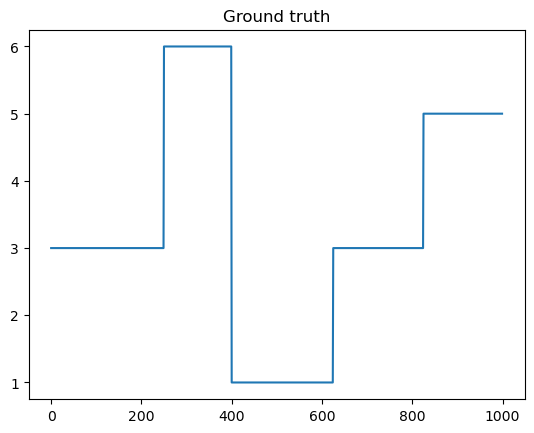

In [5]:
plt.plot(ground_truth)
plt.title("Ground truth")
plt.show()

In [6]:
# Black box operator for DCT
from jlinops import _CustomLinearOperator

class DCT1D(_CustomLinearOperator):
    """Implements a 1D dct
    """

    def __init__(self, n, type=2, norm="ortho", device="cpu"):
        
        self.type = type
        self.n_size = n
        self.norm = norm


        def _matvec(x):
            return dct(np.squeeze(x), type=self.type, norm=self.norm)
        
        def _rmatvec(x):
            return idct(np.squeeze(x), type=self.type, norm=self.norm)
        
        super().__init__( (n,n), _matvec, _rmatvec, device=device, dtype=None)


In [7]:
F = DCT1D(n)
F_explicit = jlinops.black_box_to_dense(F)

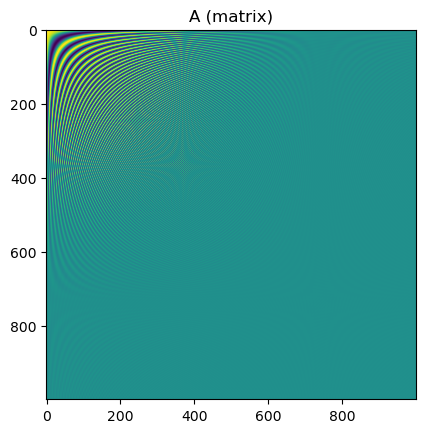

In [8]:
plt.imshow(F_explicit)
plt.title("A (matrix)")
plt.show()

In [9]:
# # Random undersampling
# np.random.seed(0)
# mask = np.random.binomial(1, 0.8, size=n)
# P = jlinops.Subsampling1DOperator(mask)

# Only first 100 components
mask = np.ones(n)
mask[25:] = 0.0
P = jlinops.Subsampling1DOperator(mask)

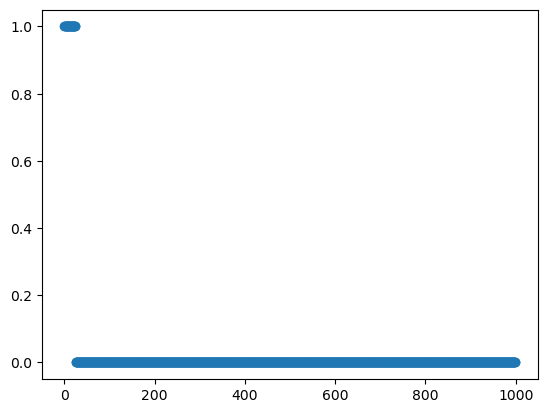

In [10]:
plt.scatter(grid, mask)
plt.show()

In [11]:
# Generate synthetic data
np.random.seed(0)
A = P @ F
b_true = A @ ground_truth
noise_sigma = 0.03*np.amax(b_true)
noise_var = noise_sigma**2
b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

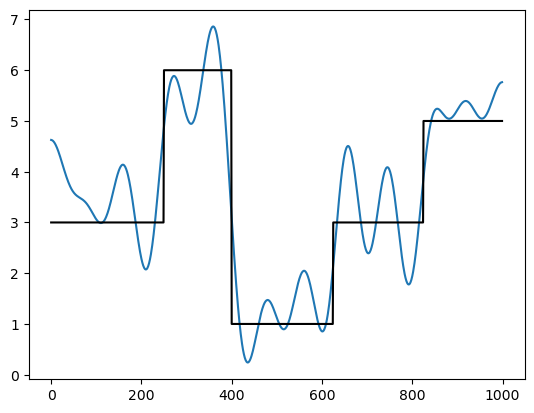

In [12]:
# Inverse DCT reconstruction
plt.plot(A.T @ b)
plt.plot(ground_truth, color="k")
plt.show()

# Run PGKS (MM)

In [131]:
q = 1.0
epsilon = 1e-4
weight_params = {
    "q": q,
    "epsilon": epsilon,
}

In [132]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

# Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="zero")
# L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

In [133]:
# Set method
method = "dp"

# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

K = jlinops.MatrixLinearOperator(Kmat)


err_norm_sq = len(b) # in expectation

# Build solver
mmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

In [138]:
data = mmgks_solver.solve(n_iter=150, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

pdata = mmgks_solver.solve_with_priorconditioning(n_iter=150, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

0.600266383637569
5.298187431191361
5.336871410064006
5.355280117484467
5.391171699166569
5.440036559534359
5.468591154193136
5.511620900500196
5.580516735718105
5.605824829453779
5.654276869399389
5.722638482794499
5.759181695716777
5.825261927297625
5.871114845785699
5.937628470469937
5.990319243830568
6.059156778276593
6.116404390104944
6.193207507712405
6.2408661460286785
6.2969472297417095
6.391532398797004
6.430302955126487
6.513344261699208
6.554163592574859
6.60671541686597
6.687529830446041
6.7426169117921155
6.789461856070751
6.846185358312258
6.902029148665505
6.949200199798232
7.013331858052184
7.067773118290039
7.103104115038364
7.1587937198625236
7.214627974841938
7.250566484081714
7.302001454468759
7.324773816461775
7.357610616855465
7.3862783758399875
7.423134050298304
7.445394508232539
7.465157290104844
7.48984489263335
7.4918366436746
7.502026431539198
7.488606614218765
7.470335614348655
7.462471549850512
7.456070710239023
7.4326724301979885
7.4007682568491555
7.37998

0.37997637204384677
2.0759855884752976
2.0610228316250905
2.060388354695854
2.0777420987791646
2.0866431922301714
2.0967931179972465
2.104406243980707
2.1120688145644357
2.1182579640915513
2.1243086410260155
2.128969742238139
2.1337433252399816
2.137966690512863
2.1414523228375337
2.145022614561852
2.1480205846613956
2.150800464048817
2.1535416555530484
2.1558149582867916
2.1581238426620573
2.1601692620483774
2.1621176745227966
2.163925672337957
2.165611825555664
2.167212526410291
2.168687554291452
2.1700979782848093
2.171405801673067
2.172650158887159
2.17381505715834
2.1749209516509476
2.1759621384030075
2.176952818082307
2.1778881397184655
2.1787801269736047
2.179626965238808
2.1804343656736633
2.1812049668304474
2.1819404129481423
2.1826447511301046
2.1833180582256904
2.1839645610799696
2.1845840121582465
2.1851797433257296
2.1857518563531255
2.1863026224818056
2.1868327070811873
2.187343691227356
2.187836335603299
2.1883118308599165
2.1887709628160277
2.189214591891188
2.189643536

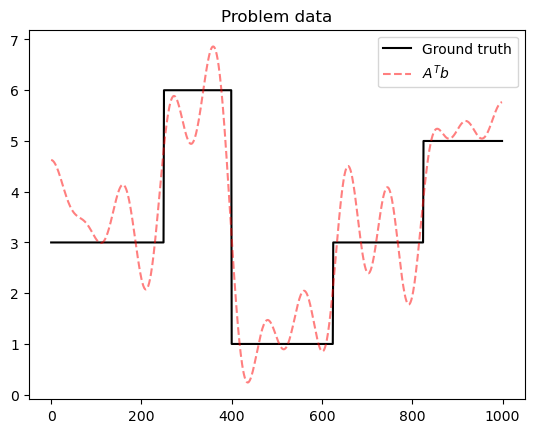

In [139]:
plt.plot(ground_truth, color="k", label="Ground truth")
plt.plot(A.T @ b, color="red", ls="--", alpha=0.5, label="$A^T b$")
plt.title("Problem data")
plt.legend()
plt.show()

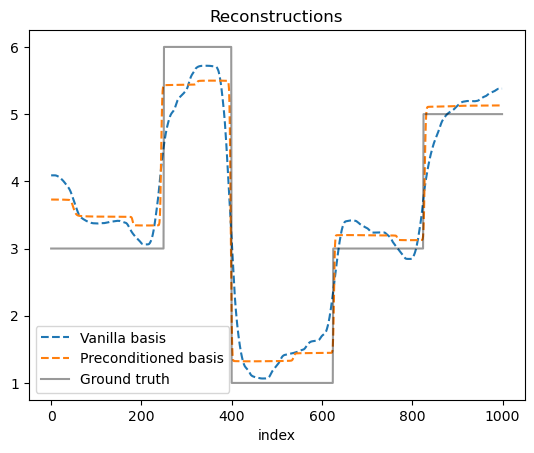

In [140]:
plt.plot(data['x'], label="Vanilla basis", ls="--")
plt.plot(pdata['x'], label="Preconditioned basis", ls="--")
plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.4)
plt.title("Reconstructions")
plt.xlabel("index")
plt.legend()
plt.show()

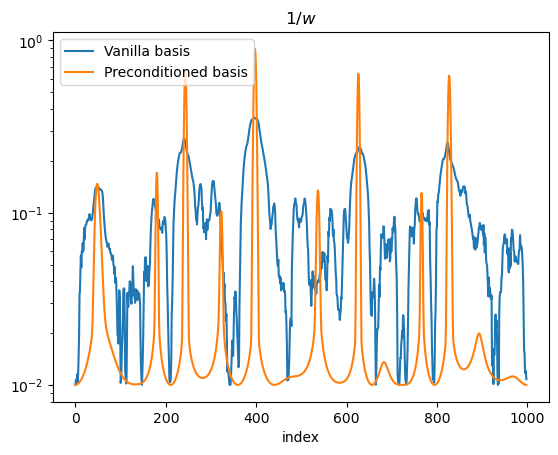

In [141]:
plt.semilogy(1.0/data['w'], label="Vanilla basis")
plt.semilogy(1.0/pdata['w'], label="Preconditioned basis")
plt.title("$1/w$")
plt.xlabel("index")
plt.legend()
plt.show()

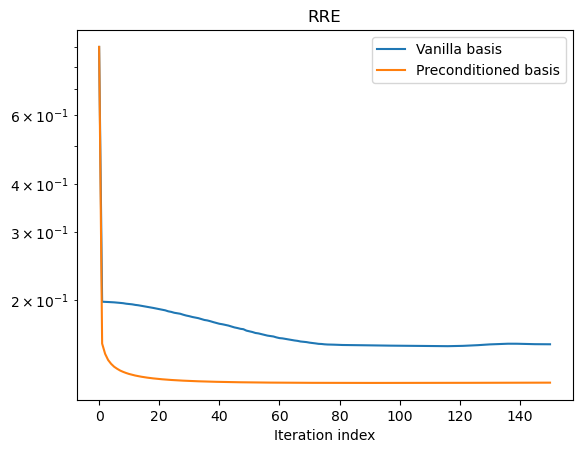

In [142]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

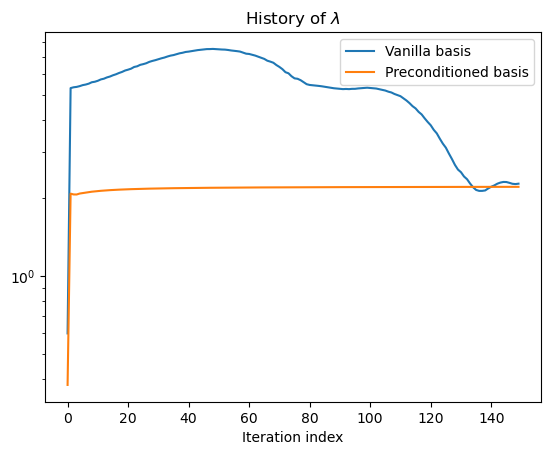

In [143]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

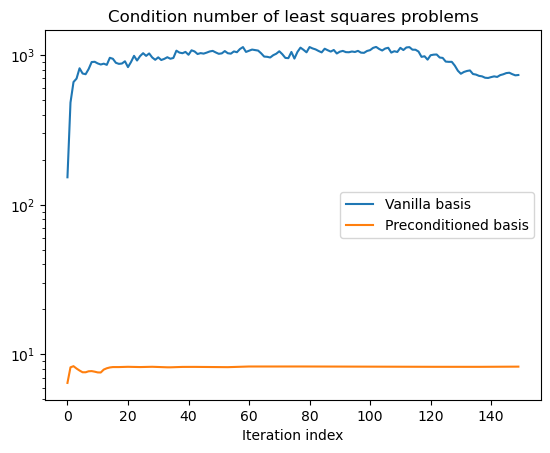

In [144]:
plt.semilogy(data["cond_ests"], label="Vanilla basis")
plt.semilogy(pdata["cond_ests"], label="Preconditioned basis")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# VGKS

In [145]:
q = 1.0
epsilon = 1e-3
weight_params = {
    "q": q,
    "epsilon": epsilon,
}

In [146]:
vmmgks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

vdata = vmmgks_solver.solve(n_iter=150, init_dim=5, x0=None, lambdah0=1e0, lambdah_max=1e7, lambdah_min=1e-7, 
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

# pdata = iasgks_solver.solve_with_priorconditioning(n_iter=100, init_dim=5, x0=ground_truth, lambdah0=1e0, lambdah_max=1e7,
#                                                  regparam="dp", x_true=ground_truth, weight_params=weight_params,
#                                                  regparam_kwargs={"eta":1.01})

95.63638774098084
99.57438470670274
109.88684373525557
117.88869085619005
117.27375191997814
105.27723067081475
91.20605752949967
82.56243960969933
77.22632752428238
73.78626577195791
71.52310959708399
70.00189550881765
68.77421921247976
67.8474818022305
67.12100093237073
66.52161661718682
66.06650132291188
65.65708217396427
65.21977227736761
64.72575767929675
64.20444407401193
63.648016913684266
63.025030078374755
62.39919398449769
61.76891307946625
61.1062013520709
60.414861441180086
59.758200144930726
59.20591959687392
58.710707922196725
58.27403110414954
57.87154097596936
57.49561183424449
57.18299382682447
56.89991952318775
56.621910489062266
56.38275035816994
56.16546499197656
55.9510905350146
55.71695508159592
55.504010345137644
55.303834485338804
55.166514036621166
55.03507035240116
54.89889571922067
54.78711020390276
54.67489134638194
54.57253921533729
54.48525259521718
54.40809847266594
54.346338469859155
54.28646441241893
54.22524539555525
54.161434257158945
54.1002589587693

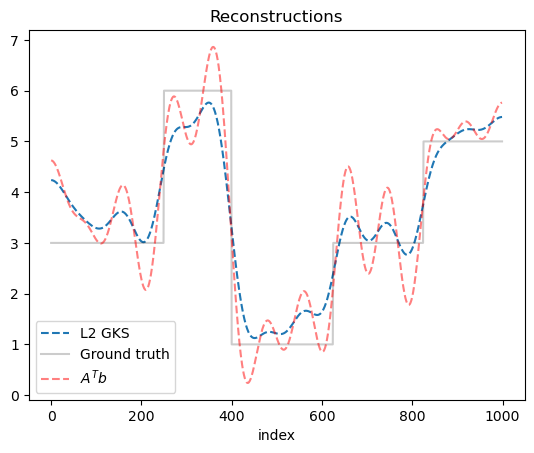

In [147]:
plt.plot(vdata['x'], label="L2 GKS", ls="--")
#plt.plot(pdata['x'], label="Preconditioned basis", ls="--")
plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.2)
plt.plot(A.T @ b, color="red", ls="--", alpha=0.5, label="$A^T b$")
plt.title("Reconstructions")
plt.xlabel("index")
plt.legend()
plt.show()

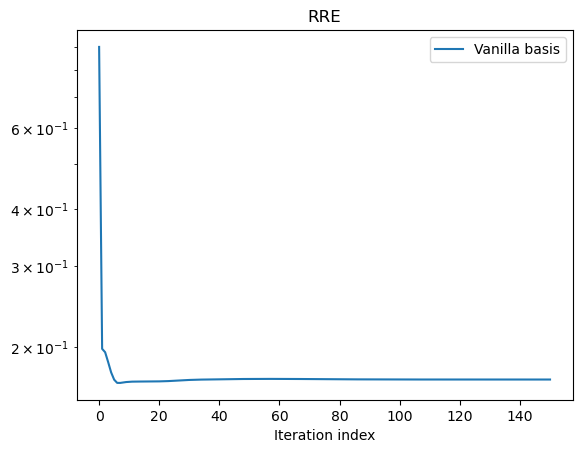

In [148]:
plt.semilogy(vdata["rre_history"], label="Vanilla basis")
#plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

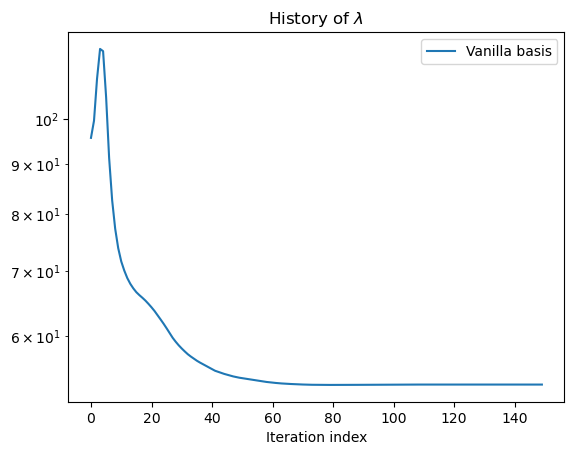

In [149]:
plt.semilogy(vdata["lambda_history"], label="Vanilla basis")
#plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# Plots

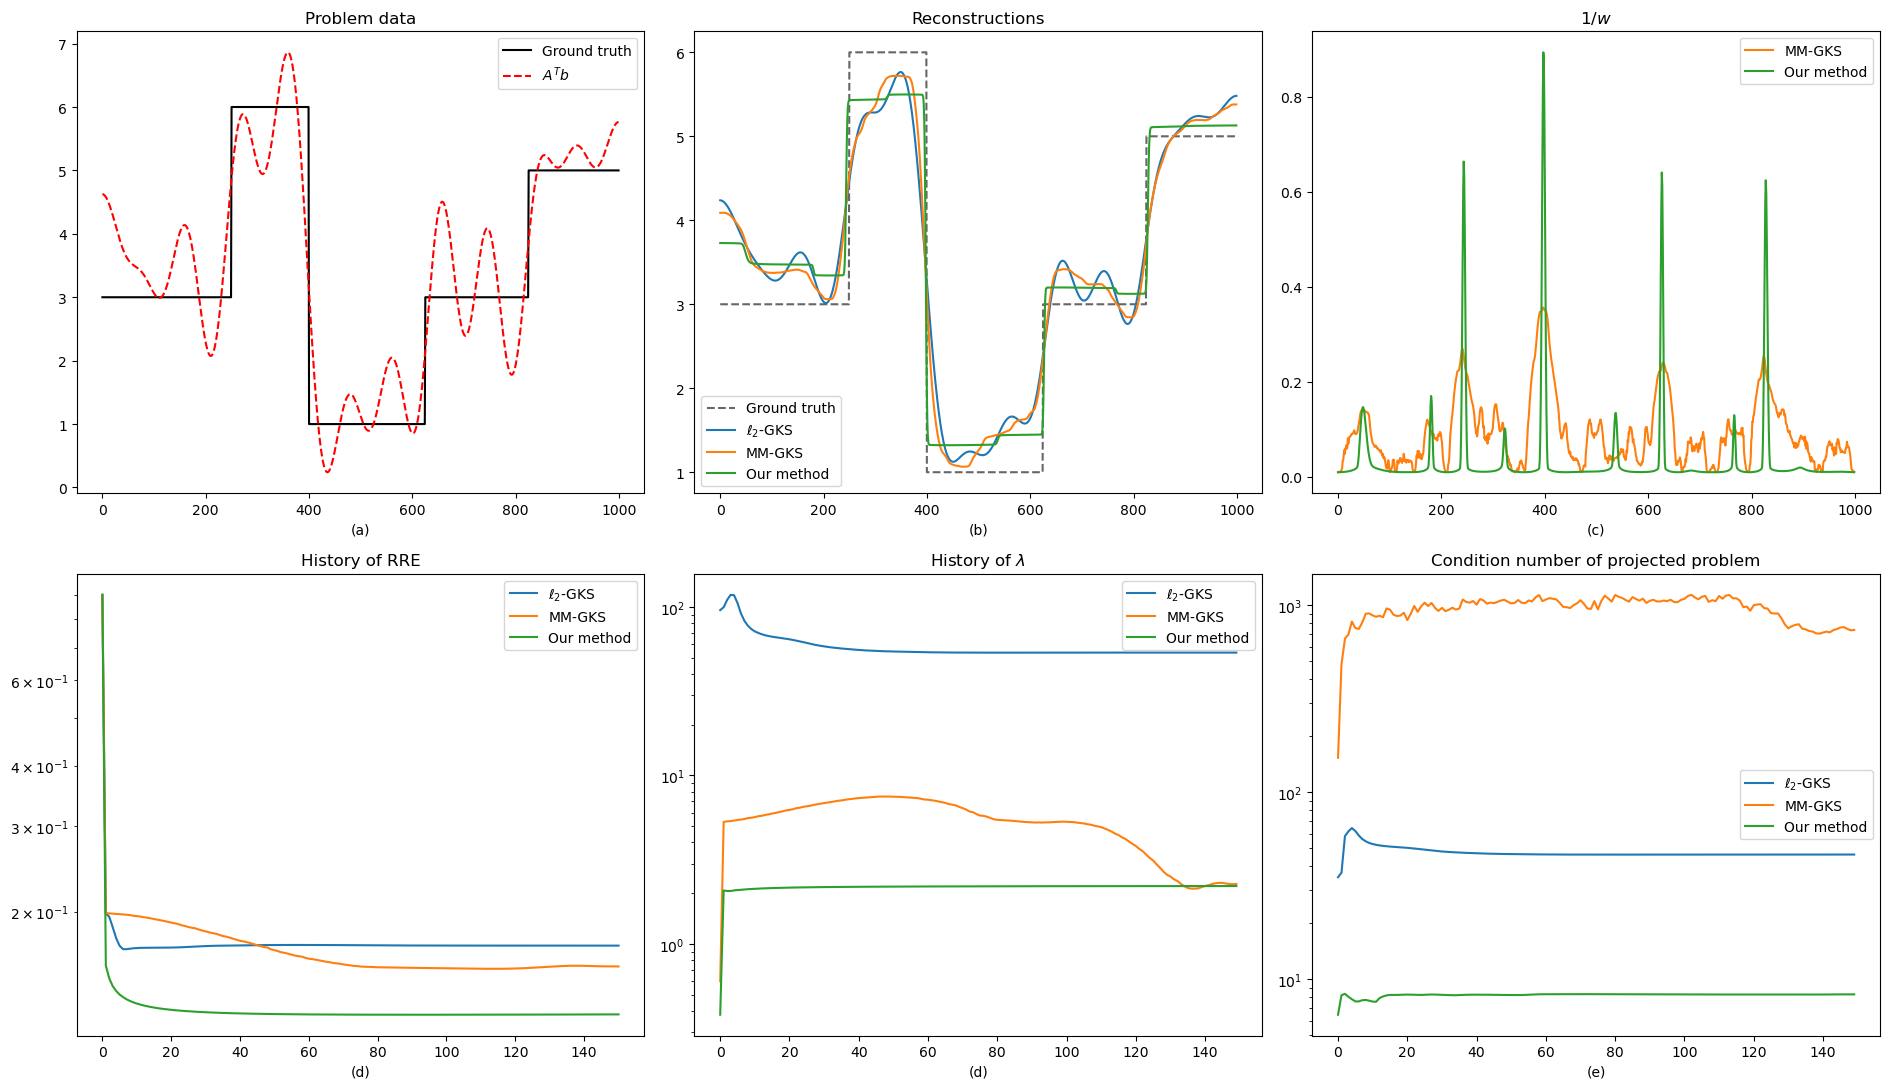

In [150]:
fig, axs = plt.subplots(2,3, figsize=(19,11))

# Data
axs[0,0].plot(ground_truth, label="Ground truth", color="k", alpha=1.0)
axs[0,0].plot(A.T @ b, color="red", ls="--", alpha=1.0, label="$A^T b$")
axs[0,0].legend()
axs[0,0].set_title("Problem data")
axs[0,0].set_xlabel("(a)")

# Reconstructions
axs[0,1].plot(ground_truth, label="Ground truth", color="k", ls="--", alpha=0.6)
axs[0,1].plot(vdata['x'], label="$\\ell_2$-GKS", ls="-")
axs[0,1].plot(data['x'], label="MM-GKS", ls="-")
axs[0,1].plot(pdata['x'], label="Our method", ls="-")
axs[0,1].set_title("Reconstructions")
axs[0,1].set_xlabel("(b)")
axs[0,1].legend(loc="lower left")

# Weights
#axs[0,1].plot(vdata['w'], label="$\\ell_2$-GKS", ls="--")
axs[0,2].plot(1.0/data['w'], label="MM-GKS", ls="-", color="C1")
axs[0,2].plot(1.0/pdata['w'], label="Our method", ls="-", color="C2")
#axs[0,1].plot(ground_truth, label="Ground truth", color="k", alpha=0.4)
axs[0,2].set_title("$1/w$")
axs[0,2].set_xlabel("(c)")
axs[0,2].legend(loc="upper right")


# RRE
axs[1,0].semilogy(vdata["rre_history"], label="$\\ell_2$-GKS")
axs[1,0].semilogy(data["rre_history"], label="MM-GKS")
axs[1,0].semilogy(pdata["rre_history"], label="Our method")
axs[1,0].set_xlabel("(d)")
axs[1,0].set_title("History of RRE")
axs[1,0].legend()


# lambdah hist
axs[1,1].semilogy(vdata["lambda_history"], label="$\\ell_2$-GKS")
axs[1,1].semilogy(data["lambda_history"], label="MM-GKS")
axs[1,1].semilogy(pdata["lambda_history"], label="Our method")
axs[1,1].set_xlabel("(d)")
axs[1,1].set_title("History of $\\lambda$")
axs[1,1].legend()



# Condition number
axs[1,2].semilogy(vdata["cond_ests"], label="$\\ell_2$-GKS")
axs[1,2].semilogy(data["cond_ests"], label="MM-GKS")
axs[1,2].semilogy(pdata["cond_ests"], label="Our method")
axs[1,2].set_xlabel("(e)")
axs[1,2].set_title("Condition number of projected problem")
axs[1,2].legend()

fig.tight_layout()

fig.savefig("1d_cosine_results.png", dpi=250, bbox_inches=None)
fig.savefig("1d_cosine_results.eps", format="eps", dpi=250, bbox_inches=None)

plt.show()